# Simulated twins, two time points: direction of regulation

With twins measured at **two time points**, TwINFER also infers the **direction** of regulation: if gene X regulates gene Y, X in one sister at an early time predicts Y in the other sister later, better than Y early predicts X later. This tutorial shows how `infer_with_twinfer` does this, how to choose the two time points and the gene pairs to test, and how to rank and draw the directed result.

The three z-scores (`z_rho`, `z_rho_s`, `z_rho_Delta`) and the inference scenarios are explained in [`inference_simulation_one_time_point.ipynb`](inference_simulation_one_time_point.ipynb); here they are computed at both time points.

**Data.** The simulation of the [one-time-point tutorial](inference_simulation_one_time_point.ipynb) (gene 1 activates gene 2, 6,000 twin pairs, 48 hours after division, `simulation_example_output_data/`). It has two genes, so there is one gene pair; with more genes, every pair is scored the same way.

## 1. Setup and data

Results are written to `tutorial_output/simulation_two_time_points/`, next to this notebook; change `output_dir` to save them elsewhere. `infer_with_twinfer(..., save_to=path)` saves its result table (`.csv`, `.csv.gz`, `.tsv` or `.parquet`) and writes the settings of the call next to it (`<name>_settings.json`); `save_result(table, path)` saves any other table the same way.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from twinfer.inference.covariance_decomposition_z_scores import infer_with_twinfer, save_result
from twinfer.inference.ranked_edges import ranked_edge_lists
from twinfer.plotting.network_plots import network_from_scenarios, plot_grn
from twinfer.utils.paths import get_repo_root

output_dir = get_repo_root() / "tutorials" / "tutorial_output" / "simulation_two_time_points"   # where the results are saved (next to this notebook)
table = pd.read_csv(get_repo_root() / "simulation_example_output_data" / "df_rows_0_0_24102026_140638_ncells_6000_A_to_B_04cf9c46.csv")
genes = ["gene_1_mRNA", "gene_2_mRNA"]
print(f"{table['clone_id'].nunique()} twin pairs, time steps {table['time_step'].min()}-{table['time_step'].max()} h")

6000 twin pairs, time steps 0-48 h


## 2. The design: three groups of clones

Each sister can be measured only once. With two time points `t_a < t_b`, `infer_with_twinfer` therefore splits the clones at random (fixed `seed`; proportions `split`, default 1:1:2) into

* twin pairs with both sisters measured at `t_a` (`N_a`);
* twin pairs with both sisters measured at `t_b` (`N_b`);
* a **cross group**, with one sister measured at `t_a` and the other at `t_b` (`N_cross`).

The covariance z-scores at each time point (suffix `_ta` for `t_a`, `_tb` for `t_b`) use all cells measured at that time, as for real lineage-tracing data: `z_rho` uses the twin pairs of that group and the cross-group sister measured then as a singleton (`N_clones_ta`, `N_clones_tb` clones in total); `z_rho_s` and `z_rho_Delta` need both sisters, so they use the twin pairs of that group.

In the cross group:

* `rho_dag_xy`: Spearman correlation of X in one sister at `t_a` with Y in the other sister at `t_b`; `rho_dag_yx` the other way round; `z_dag = rho_dag × sqrt(N_cross - 1)`;
* `delta = |rho_dag_xy| - |rho_dag_yx|`: positive when X → Y, negative when Y → X. The magnitudes are compared, so a repression (negative `rho_dag`) gets its direction the same way as an activation;
* `p_delta`: permutation p-value of `delta` (`n_permutations`, default 1,000): the cross group is permuted, each null value is built the same way, `|rho_dag_xy| - |rho_dag_yx|` of the permuted pairs, and `p_delta` is the share of permutations with |null| ≥ |`delta`| (+1 in numerator and denominator; the smallest possible value is 1/1001).

As in the paper, the two time points are **1 hour** (`t_a`) and **20 hours** (`t_b`) after division.

In [2]:
result = infer_with_twinfer(table, genes, time_points=[1, 20], save_to=output_dir / "z_scores_1h_20h.csv")
result[["gene_x", "gene_y", "N_a", "N_b", "N_cross", "N_clones_tb", "z_dag_xy", "z_dag_yx", "delta", "p_delta",
        "inference_scenario_ta", "inference_scenario_tb"]]

,gene_x,gene_y,N_a,N_b,N_cross,N_clones_tb,z_dag_xy,z_dag_yx,delta,p_delta,inference_scenario_ta,inference_scenario_tb
0,gene_1_mRNA,gene_2_mRNA,1500,1500,3000,4500,4.800621,-0.883403,0.07153,0.000999,2,2


`z_dag_xy` is large and `z_dag_yx` is close to 0: gene 1 at 1 hour predicts gene 2 at 20 hours, not the reverse, so the direction gene 1 → gene 2 is recovered (`p_delta` at its minimum).

The scenario is reported for both twin groups (`inference_scenario_ta`, `inference_scenario_tb`); at 20 hours the pair is in scenario 2, regulation.

## 3. Other time points

The paper uses 1 and 20 hours. For other systems (other kinetics, other sampling times) the choice may differ: the first time point should be early, when the two sisters are still almost identical, so that one sister at `t_a` stands for the other; the second late enough for the regulation to act. Scanning the second time point for gene 1 and gene 2 in this simulation, with the first at 1 hour:

In [3]:
rows = []
# for t_a, t_b in [(1, 2), (1, 5), (1, 10), (1, 20), (1, 30), (1, 48), (5, 20), (10, 20)]:   # [2026-10-24 replaced: later first time points removed]
for t_a, t_b in [(1, 2), (1, 5), (1, 10), (1, 20), (1, 30), (1, 48)]:
    r = infer_with_twinfer(table, genes, time_points=[t_a, t_b]).iloc[0]
    rows.append(dict(t_a=t_a, t_b=t_b, z_dag_xy=r.z_dag_xy, z_dag_yx=r.z_dag_yx, delta=r.delta, p_delta=r.p_delta))
time_point_scan = pd.DataFrame(rows)
time_point_scan.round(3)

,t_a,t_b,z_dag_xy,z_dag_yx,delta,p_delta
0,1,2,3.071,0.616,0.045,0.009
1,1,5,5.011,-0.209,0.088,0.001
2,1,10,4.997,-1.224,0.069,0.001
3,1,20,4.801,-0.883,0.072,0.001
4,1,30,5.396,0.421,0.091,0.001
5,1,48,4.311,-1.055,0.059,0.002


With the first time point at 1 hour, the direction is significant for every second time point, already at 2 hours, one hour after the first (there `p_delta` is larger, 0.009, than from 5 hours on).

With more than two time points in `time_points`, every pair of them is scored (one row per gene pair and time pair).

## 4. Many genes: which pairs to test, ranked lists

These two options matter when many genes are scored; with the single pair of this simulation they are only described.

**Which pairs get the cross-time correlation.** The permutation test makes the cross-time correlation the slowest part. It can be limited with `cross_correlation_pairs` (the other pairs get NaN in the cross-time columns):

* `"all"` (default): every gene pair;
* `"significant_rho"`: pairs whose `z_rho` is significant at `t_b`;
* `"regulation"`: pairs in scenario 2 or 3 at `t_b`.

```python
result = infer_with_twinfer(table, genes, time_points=[1, 20], cross_correlation_pairs="regulation")
```

**Ranked lists.** With two time points, `ranked_edge_lists` returns, besides the lists ranked by |`z_rho_s`| and |`z_rho_Delta`|, a list ranked by the cross-time correlation `z_dag`, one row per direction found, written as source → target (`z_dag_xy` for gene_x → gene_y, `z_dag_yx` for the reverse). The direction rule (`pair_directions`, also used by the network of section 5) depends on the scenario at `t_b`:

* **scenario 2** (regulation): each direction is tested on its own, |`z_dag`| > 1.96 (`z_dag_threshold`). Both can be listed: mutual regulation;
* **scenario 3** (regulation + a shared state): a shared state correlates both directions by itself, so only the difference is used: one direction, the sign of `delta`, when `p_delta < 0.05` (`direction_alpha`);
* no direction found: one row, the larger |`z_dag`|, with `directed` False.

Only pairs with a significant `z_rho` (at `t_b`) are ranked, unless `significant_rho_only=False`. For the pair here:

In [4]:
lists = ranked_edge_lists(result)
lists["z_dag"]

,rank,source,target,directed,z_dag,z_dag_xy,z_dag_yx,delta,p_delta,z_rho,inference_scenario
0,1,gene_1_mRNA,gene_2_mRNA,True,4.800621,4.800621,-0.883403,0.07153,0.000999,1.977758,2


## 5. Directed network

`network_from_scenarios` draws scenarios 2 and 3 as solid edges and scenario 4 as dashed edges, using the scenario at `t_b` (`time="tb"`, default). A solid edge gets its direction by the rule of section 4: in scenario 2 each direction with |`z_dag`| > 1.96 is drawn (two curved edges for mutual regulation), in scenario 3 one direction when `p_delta < 0.05`; otherwise it is drawn without direction. Colour = the `z_dag` of the drawn direction (`weight=None`, default; `z_rho_Delta` with one time point); its sign gives an activation arrow or a repression bar.

A mutual repression (toggle switch) usually ends up in scenario 4: its two states are a shared state of the sisters, and both cross-time correlations are then large without telling regulation from the state (two states without regulation look the same), so it is drawn dashed, without direction.

,source,target,weight,inference_scenario,line_style,directed,z_dag
0,gene_1_mRNA,gene_2_mRNA,4.800621,2,solid,True,4.800621


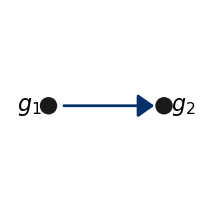

In [5]:
plot_kwargs, edges = network_from_scenarios(result)
plot_kwargs["node_labels"] = ["$g_1$", "$g_2$"]
fig, ax = plt.subplots(figsize=(4.5, 2.5))
plot_grn(**plot_kwargs, ax=ax, fixed_pos={0: (0.2, 0.5), 1: (0.8, 0.5)}, show_colorbar=False, figsize=(8, 8))   # figsize sets line and arrow scale
edges

Gene 1 → gene 2 is drawn as a directed edge (activation, positive `z_dag`). Compare the one-time-point tutorial, where the same pair is drawn without direction.

## 6. Save the results

The scores at 1 and 20 hours (already written by `save_to` in section 2), the time-point scan, the ranked lists, the network edges and the network figure.

In [6]:
save_result(time_point_scan, output_dir / "time_point_scan.csv")
for score, ranked in lists.items():
    save_result(ranked, output_dir / f"ranked_by_{score}.csv")
save_result(edges, output_dir / "network_1h_20h_edges.csv")
fig.savefig(output_dir / "network_1h_20h.pdf", bbox_inches="tight")
sorted(p.name for p in output_dir.iterdir())

['network_1h_20h.pdf',
 'network_1h_20h_edges.csv',
 'ranked_by_z_dag.csv',
 'ranked_by_z_rho_Delta.csv',
 'ranked_by_z_rho_s.csv',
 'time_point_scan.csv',
 'z_scores_1h_20h.csv',
 'z_scores_1h_20h_settings.json']

## Summary

| step | call |
|---|---|
| covariance z-scores at both times + direction | `infer_with_twinfer(table, genes, time_points=[t_a, t_b])` |
| limit the cross-time correlation | `cross_correlation_pairs="significant_rho"` or `"regulation"` |
| ranked lists, including the cross-time correlation | `ranked_edge_lists(result)` |
| directed network | `plot_grn(**network_from_scenarios(result)[0])` |
| save the scores | `infer_with_twinfer(..., save_to="scores.csv")`, or `save_result(table, "table.csv")` |

For real lineage-tracing data (clones instead of exact twins), see [`inference_real_data_lineage_tracing.ipynb`](inference_real_data_lineage_tracing.ipynb); there, each time point is scored on its own.